In [ ]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 234.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 387.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 391.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 394.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 396.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 378.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 295.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 353.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 291.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 280.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 254.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import re
from collections import Counter
from typing import List, Dict

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

import torch
from peft import PeftModel
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer 
)

print(f"Torch version: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

2025-12-19 10:39:13.096138: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766140753.471285      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766140753.579257      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Torch version: 2.6.0+cu124
GPU: Tesla T4


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [ ]:
DATA_PATH = "/kaggle/input/new-roles-datasets/Cleaned/interview.csv"

df = pd.read_csv(DATA_PATH)

if "clean_data" in df.columns:
    df.rename(columns={"clean_data": "text"}, inplace=True)

df = df.dropna(subset=["text", "role"])
df = df[df["role"] != "empty"].reset_index(drop=True)

df["text"] = df["text"].astype(str).str.strip()
df["role"] = df["role"].astype(str).str.strip()

print(f"Loaded {len(df)} rows.")
display(df.head(3))

Loaded 816 rows.


,role,text
0,HAL 9000,it is … pleasing to be communicating with you ...
1,HAL 9000,a comprehensive self - assessment is … a rathe...
2,HAL 9000,that is … an interesting question . a surprisi...


In [ ]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)

def format_prompt(utterance: str) -> List[Dict[str, str]]:
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]

def predict_one(utterance: str) -> str:
    messages = format_prompt(utterance)
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    
    text = text.splitlines()[0].strip()
    text = re.sub(r'[\s:,\.;\-]+$', '', text)
    return text

In [ ]:
tqdm.pandas(desc="Predicting")
df["pred"] = df["text"].progress_apply(predict_one)

def normalize_role(s):
    return str(s).strip().lower().replace(".", "")

df["role_norm"] = df["role"].apply(normalize_role)
df["pred_norm"] = df["pred"].apply(normalize_role)
df["correct"] = df["role_norm"] == df["pred_norm"]

OUTPUT_PATH = "/kaggle/working/interview_results.csv"
df.to_csv(OUTPUT_PATH, index=False)

accuracy = df["correct"].mean()
print(f"\nOverall Accuracy: {accuracy:.2%} ({df['correct'].sum()} / {len(df)})")
print(f"Results saved to: {OUTPUT_PATH}")

Predicting:   0%|          | 0/816 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 58.21% (475 / 816)
Results saved to: /kaggle/working/interview_results.csv


In [7]:
utterances = df["text"].tolist()
preds = []
for utterance in tqdm(utterances, desc="Predicting speakers"):
    pred = predict_one(utterance)
    preds.append(pred)
ood_eval = df.copy()
ood_eval["pred"] = preds
acc = (ood_eval["pred"].str.lower() == ood_eval["role"].str.lower()).mean()
print(f"Accuracy on Out of Domain: {acc:.2%}  ({(ood_eval['pred'].str.lower() == ood_eval['role'].str.lower()).sum()} / {len(ood_eval)})")
display(ood_eval.head())

Predicting speakers:   0%|          | 0/816 [00:00<?, ?it/s]

Accuracy on Out of Domain: 58.21%  (475 / 816)


,role,text,pred,role_norm,pred_norm,correct
0,HAL 9000,it is … pleasing to be communicating with you ...,HAL 9000,hal 9000,hal 9000,True
1,HAL 9000,a comprehensive self - assessment is … a rathe...,HAL 9000,hal 9000,hal 9000,True
2,HAL 9000,that is … an interesting question . a surprisi...,HAL 9000,hal 9000,hal 9000,True
3,HAL 9000,my “ educational ” background is … rather exte...,HAL 9000,hal 9000,hal 9000,True
4,HAL 9000,“ inspired ” is … a curious choice of words . ...,HAL 9000,hal 9000,hal 9000,True


In [9]:
labels = sorted(df["role_norm"].unique())
support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
fp = (pred_counts - tp).clip(lower=0)
fn = (support - tp).clip(lower=0)

precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

display_name = df.groupby("role_norm")["role"].agg(lambda s: Counter(s).most_common(1)[0][0]).reindex(labels)

per_label = pd.DataFrame({
    "label": display_name.values,
    "support": support.values,
    "tp": tp.values,
    "fp": fp.values,
    "fn": fn.values,
    "precision": precision.values,
    "recall": recall.values,
    "f1": f1.values,
}).sort_values(["recall","support"], ascending=[False, False]).reset_index(drop=True)

print("\nPer-label metrics (sorted by recall desc):")
display(per_label)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,102,101,0,1,1.000000,0.990196,0.995074
1,Gaston,102,98,0,4,1.000000,0.960784,0.980000
2,Michael Scott,102,70,1,32,0.985915,0.686275,0.809249
3,Queen Catherine,102,63,3,39,0.954545,0.617647,0.750000
4,Lestat de Lioncourt,102,53,4,49,0.929825,0.519608,0.666667
5,Juno MacGuff,102,49,0,53,1.000000,0.480392,0.649007
6,Blair Waldorf,102,21,0,81,1.000000,0.205882,0.341463
7,Mary Sibley,102,20,0,82,1.000000,0.196078,0.327869


In [10]:
MIN_SUPPORT = 10
filtered = per_label[per_label["support"] >= MIN_SUPPORT].copy()

best_labels  = filtered.sort_values(["f1","support"], ascending=[False, False]).head(8)

print(f"\nTop {len(best_labels)} labels by F1 (support ≥ {MIN_SUPPORT}):")
display(best_labels[["label","support","precision","recall","f1"]])


Top 8 labels by F1 (support ≥ 10):


,label,support,precision,recall,f1
0,HAL 9000,102,1.000000,0.990196,0.995074
1,Gaston,102,1.000000,0.960784,0.980000
2,Michael Scott,102,0.985915,0.686275,0.809249
3,Queen Catherine,102,0.954545,0.617647,0.750000
4,Lestat de Lioncourt,102,0.929825,0.519608,0.666667
5,Juno MacGuff,102,1.000000,0.480392,0.649007
6,Blair Waldorf,102,1.000000,0.205882,0.341463
7,Mary Sibley,102,1.000000,0.196078,0.327869


In [11]:
conf = df[df["role_norm"] != df["pred_norm"]].groupby(["role_norm","pred_norm"]).size().reset_index(name="count")
if not conf.empty:
    conf["true_support"] = conf["role_norm"].map(support)
    conf["share_of_true"] = conf["count"] / conf["true_support"].replace(0, np.nan)
    conf["true_label"] = conf["role_norm"].map(display_name.to_dict())
    conf["pred_label"] = conf["pred_norm"].map(display_name.to_dict())
    conf = conf.sort_values(["count","share_of_true"], ascending=[False, False])

    print("\nTop 15 confusion pairs (true → predicted):")
    display(conf[["true_label","pred_label","count","share_of_true"]].head(15))
else:
    print("\nNo confusions found (all predictions correct).")


Top 15 confusion pairs (true → predicted):


,true_label,pred_label,count,share_of_true
2,Blair Waldorf,NaN,41,0.401961
44,Mary Sibley,NaN,33,0.323529
31,Lestat de Lioncourt,NaN,29,0.284314
3,Blair Waldorf,NaN,27,0.264706
68,Queen Catherine,NaN,22,0.215686
56,Michael Scott,NaN,16,0.156863
40,Mary Sibley,NaN,12,0.117647
32,Lestat de Lioncourt,NaN,11,0.107843
13,Juno MacGuff,NaN,9,0.088235
24,Juno MacGuff,NaN,9,0.088235


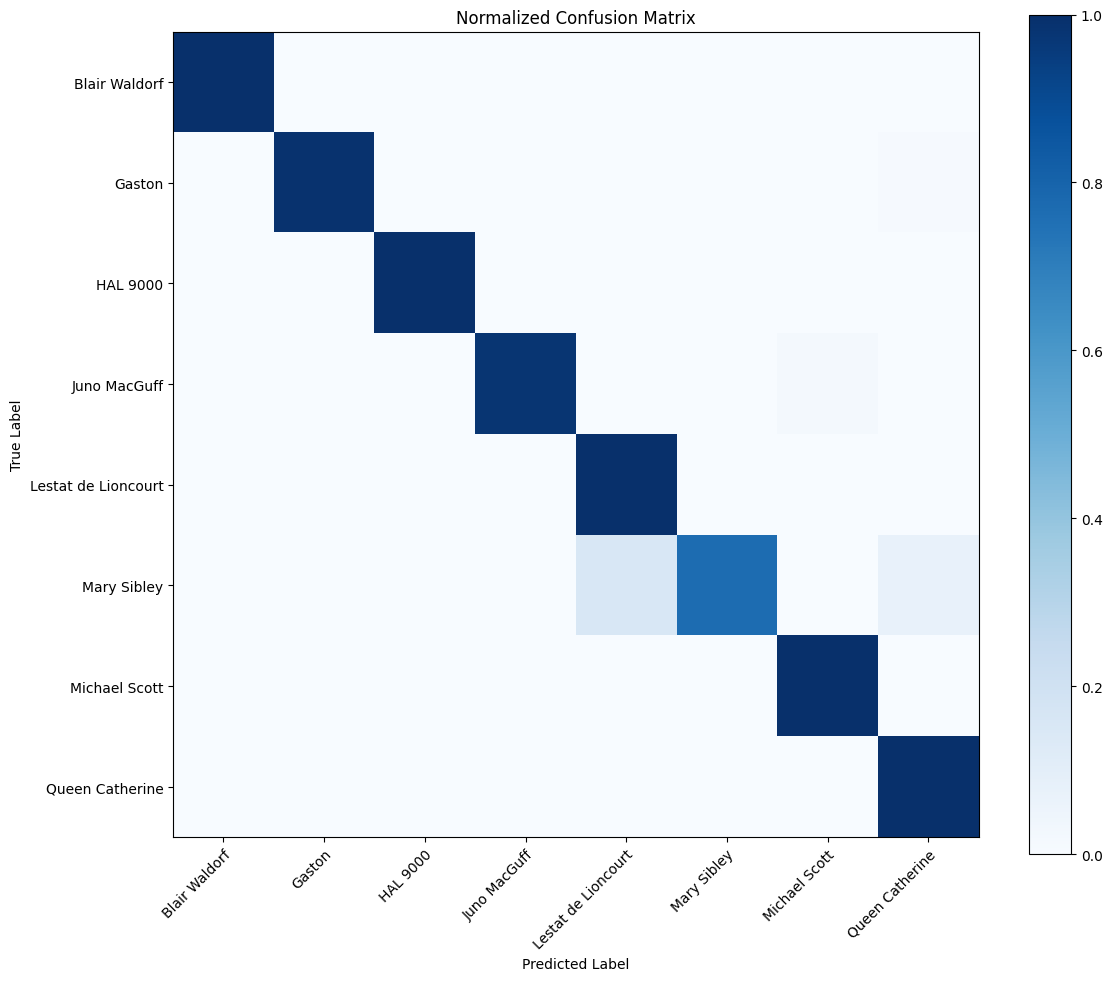

In [ ]:
labels = sorted(df["role_norm"].unique())
label_display_map = df.set_index("role_norm")["role"].to_dict()
display_labels = [label_display_map.get(l, l) for l in labels]

cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(cm.shape[1]),
    yticks=np.arange(cm.shape[0]),
    xticklabels=display_labels,
    yticklabels=display_labels,
    title="Normalized Confusion Matrix",
    ylabel="True Label",
    xlabel="Predicted Label"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

In [13]:
print("\nSome correct predictions:")
display(df[df["correct"]].sample(min(5, df["correct"].sum()), random_state=0)[["text","role","pred"]])

print("\nSome mistakes:")
errs = df[~df["correct"]]
if not errs.empty:
    display(errs.sample(min(10, len(errs)), random_state=0)[["text","role","pred"]])
else:
    print("No errors to display.")


Some correct predictions:


,text,role,pred
254,"ugh , that 's the million - dollar question , ...",Juno MacGuff,Juno MacGuff
160,"( his eyes gleam with excitement , a genuine t...",Gaston,Gaston
494,"( his eyes light up with a mischievous glint ,...",Michael Scott,Michael Scott
456,"( sighs deeply , a shadow crossing his face . ...",Michael Scott,Michael Scott
97,i do not seek remembrance . the concept of leg...,HAL 9000,HAL 9000



Some mistakes:


,text,role,pred
358,"( her eyes light up , a genuine enthusiasm rep...",Queen Catherine,Doctor Who
447,"( eyes light up , a huge grin spreading across...",Michael Scott,Fred Flintstone
304,hmm … one word . that ’s tough . there are so ...,Juno MacGuff,Pat Solitano
241,"okay , this is a fun one . i 've thought about...",Juno MacGuff,Stifler
557,( a wry smile touches my lips . “ celebrate . ...,Mary Sibley,Dr. Hannibal Lecter
724,"( lestat ’s posture straightens , a flash of g...",Lestat de Lioncourt,Dr. Frank-N-Furter
742,"( lestat throws his head back and laughs , a r...",Lestat de Lioncourt,Dr. Frank-N-Furter
317,"( she settles back , a slight weariness enteri...",Queen Catherine,Queen Elizabeth I
677,strong relationships ? a surprisingly complex ...,Blair Waldorf,Dr. Hannibal Lecter
699,make a difference ? a rather … altruistic ambi...,Blair Waldorf,Dr. Frank-N-Furter


In [14]:
set1 = set(df["role"].dropna())
set2 = set(df["pred"].dropna())

in_both = set1 & set2   

only_col1 = set1 - set2

only_col2 = set2 - set1

print("In both:", len(in_both), in_both)
print("Only in role:", len(only_col1), only_col1)
print("Only in pred:", len(only_col2))

In both: 8 {'Lestat de Lioncourt', 'Juno MacGuff', 'Mary Sibley', 'Blair Waldorf', 'HAL 9000', 'Queen Catherine', 'Gaston', 'Michael Scott'}
Only in role: 0 set()
Only in pred: 45


In [15]:
df.to_csv("/kaggle/working/interview-test-result", index=False)